# Mini NPU 행렬 곱 시뮬레이션

MAC(곱셈-누산) 연산을 하나씩 수행하는 방식으로 행렬 곱을 계산하고, 걸린 사이클 수를 센다.


In [1]:
ARRAY_SIZE = 4          # MAC 배열 한 변 크기(4x4)

A = [[1, 2, 3, 4],
     [5, 6, 7, 8],
     [1, 0, 1, 0],
     [2, 1, 0, 1]]

B = [[1, 0, 2, 1],
     [0, 1, 1, 0],
     [1, 1, 0, 2],
     [2, 0, 1, 1]]
print("MAC 배열", ARRAY_SIZE, "x", ARRAY_SIZE)


MAC 배열 4 x 4


## NPU 방식 행렬 곱

`npu_matmul` 은 출력 원소마다 MAC 을 n 번 수행해 누산한다.


In [2]:
def npu_matmul(A, B):
    """MAC 연산을 한 번에 하나씩 수행하며 행렬 곱을 계산하고 사이클 수를 센다."""
    n = len(A)
    C = [[0] * n for _ in range(n)]
    cycles = 0
    for i in range(n):
        for j in range(n):
            for k in range(n):
                acc = 0
                acc += A[i][k] * B[k][j]
                cycles += 1
            C[i][j] = acc
    return C, cycles


C, cycles = npu_matmul(A, B)
for row in C:
    print(row)
print("cycles:", cycles)


[8, 0, 4, 4]
[16, 0, 8, 8]
[0, 0, 0, 0]
[2, 0, 1, 1]
cycles: 64


## 기준 결과와 비교


In [3]:
def reference_matmul(A, B):
    n = len(A)
    return [[sum(A[i][k] * B[k][j] for k in range(n)) for j in range(n)] for i in range(n)]


ref = reference_matmul(A, B)
for row in ref:
    print(row)
print("일치:", C == ref)


[12, 5, 8, 11]
[28, 13, 24, 27]
[2, 1, 2, 3]
[4, 1, 6, 3]
일치: False


## 배열 크기별 사이클 수


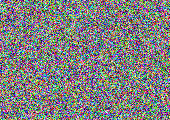

In [4]:
import matplotlib.pyplot as plt

sizes = [2, 3, 4, 5, 6, 7, 8]
cycle_counts = [npu_matmul([[1] * n for _ in range(n)], [[1] * n for _ in range(n)])[1] for n in sizes]
plt.plot(sizes, cycle_counts, marker="o")
plt.xlabel("array size")
plt.ylabel("cycles")
plt.title("MAC cycles by array size")
plt.show()


## 정리

NPU 결과가 기준 결과와 다르다. 누산 과정을 다시 확인해야 한다.
